### 🔹 핵심 질문 1: **왜 수도권을 떠났는가?**

- → **③ 수도권 → 비수도권 이주자 분석**

### 🔹 핵심 질문 2: **왜 비수도권에 남아있었는가?**

- → **① 비수도권 정착자 분석**
- → **② 비수도권 내 이주자 분석**

### 🔹 핵심 질문 3: **수도권 쏠림 해법이 가능한가?**

- → **④ 비수도권 → 수도권 이주자 분석**

| 구분 | 대상 정의 | 사용할 데이터 | 분석 목적 |
| --- | --- | --- | --- |
| **① 비수도권 내 정착자** | 5년 전~현재 **동일한 비수도권 지역** 거주자 | 2020, 2023 | 이사 없는 이유, 정착의 요인 및 만족 요인 분석 |
| **② 비수도권 내 이주자** | **비수도권 → 비수도권** 이동자 | 2023 | 비수도권 내 지역 간 이동 사유 및 만족도 변화 탐색 |
| **③ 수도권 → 비수도권 이주자** | 5년 전 **수도권**, 현재 **비수도권** 거주자 | 2020 | 수도권 이탈 동기, 탈수도권의 특성 파악 |
| **④ 비수도권 → 수도권 이주자** | 직전 거주지: **비수도권**, 현재: **수도권** | 2023 | 수도권 유입 동기, 주거환경 비교, 수도권 쏠림 배경 분석 |

#  수도권 → 비수도권 이주자 분석 (2020)

## 목적:
### 수도권을 떠난 이주자들의 특성 및 이탈 사유, 생활 조건을 분석하여 탈수도권 현상의 동인(요인)을 밝히는 것이 목적입니다.

## 분석 절차
✅ Step 1: 수도권 ↔ 비수도권 지역 정의
수도권 시도: 서울특별시, 인천광역시, 경기도

비수도권 시도: 나머지 지역

✅ Step 2: 이주자 분류 기준 설정
5년전거주지_다른시도_LABEL을 이용해 5년 전 주소가 수도권인지 확인

행정구역시도코드_LABEL로 현재 주소가 비수도권인지 확인

→ 이 두 조건을 만족하는 사람 = 수도권 → 비수도권 이주자

✅ Step 3: 이주자 특성 분석
인구적 특성: 연령, 성별, 가족 관계, 출생지

사회적 특성: 교육수준, 직업, 산업, 경제활동

이주형태: 통근/통학 거리 및 교통수단 변화

생활 조건: 자녀 돌봄 방식, 활동 제약 등

✅ Step 4: 수도권 유지자 및 비수도권 정착자와 비교
이탈하지 않은 수도권 거주자(정착자)와 비교하여 특성 차이 도출

In [ ]:
import pandas as pd

# Reload the 2020 dataset after environment reset
file_path_1 = "인구주택총조사_2%_인구사항(제공)_2020.csv"
df = pd.read_csv(file_path_1, encoding='cp949', low_memory=False)

# Define 수도권 시도 목록
capital_regions = ['서울특별시', '인천광역시', '경기도']

# 수도권 → 비수도권 이주자 추출
migrated_from_capital = df[
    (df['5년전거주지_다른시도_LABEL'].isin(capital_regions)) &  # 과거 수도권
    (~df['행정구역시도코드_LABEL'].isin(capital_regions))       # 현재 비수도권
]

# 이주자 수 확인 및 컬럼 미리보기
migrated_from_capital.shape, migrated_from_capital[['행정구역시도코드_LABEL', '5년전거주지_다른시도_LABEL']].head()


((4981, 170),
    행정구역시도코드_LABEL 5년전거주지_다른시도_LABEL
 27        제주특별자치도               경기도
 34           전라남도             서울특별시
 35          울산광역시               경기도
 38          부산광역시               경기도
 49           경상북도             서울특별시)

In [ ]:
# 수도권 → 비수도권 이주자 추출 완료
# 총 4,981명이 5년 전 수도권에서 현재 비수도권으로 이주한 이주자입니다.

# 이들은 바로 탈수도권 이주자 집단이며, 본 분석의 핵심 대상

In [ ]:
# 주요 변수 분포 요약을 위해 대상 변수 선택
selected_columns = [
    '만연령', '성별코드', '가구주와의 관계_LABEL',
    '출생지(태어난 곳)_LABEL', '교육정도_LABEL', '경제활동상태_LABEL',
    '직업대분류_LABEL', '산업대분류_LABEL', '혼인상태_LABEL'
]

# 각 변수에 대한 빈도수 요약
distribution_summary = {col: migrated_from_capital[col].value_counts(dropna=False).head(10) for col in selected_columns}

# 변환하여 시각화하기 좋은 형태로 정리
distribution_df = pd.DataFrame({k: v for k, v in distribution_summary.items()})
distribution_df.

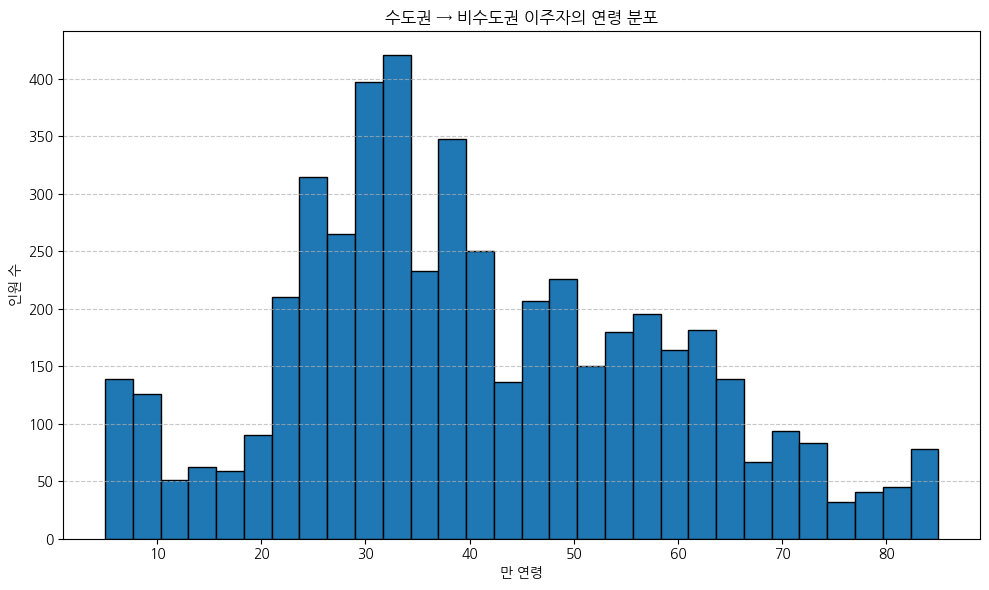

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')
plt.rcParams['font.family']= 'NanumGothic' 
plt.rcParams['axes.unicode_minus']=False


# 연령 데이터 추출 및 전처리
age_data = pd.to_numeric(migrated_from_capital['만연령'], errors='coerce').dropna()

# 연령 분포 시각화
plt.figure(figsize=(10, 6))
plt.hist(age_data, bins=30, edgecolor='black')
plt.title('수도권 → 비수도권 이주자의 연령 분포')
plt.xlabel('만 연령')
plt.ylabel('인원 수')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


* 20대 후반~30대 중반 인구가 가장 두드러진 이주 비중을 차지

* 이는 경제적 독립, 결혼, 자녀 출산 등 생애 주기적 전환기와 맞물려 있음

* 40~50대도 일정 비율로 나타나며, 이는 귀향 혹은 전원생활 전환형 이주 가능성

* 60대 이상의 고령층은 상대적으로 적음 → 비수도권 정착은 주로 청장년층 중심

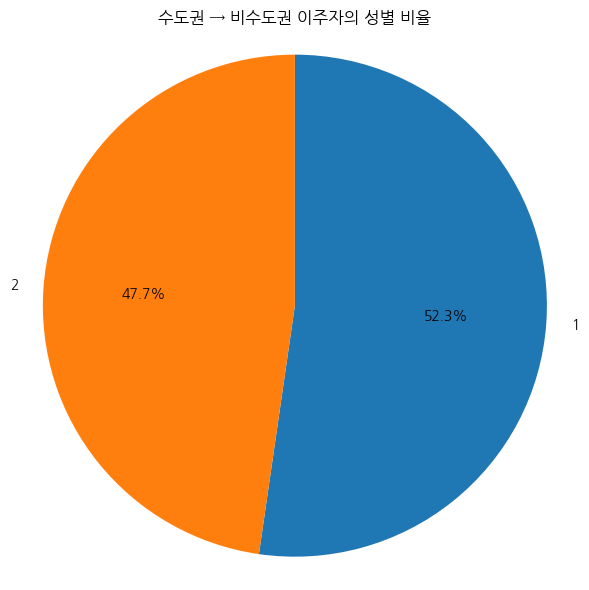

In [ ]:
# 성별 데이터 시각화
gender_counts = migrated_from_capital['성별코드'].value_counts()

# 성별 코드: 1 = 남자, 2 = 여자 (2020 조사 기준)
labels = ['1', '2']
sizes = [gender_counts.get(0, 0), gender_counts.get(1, 0)]

# 파이차트 생성
plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, counterclock=False)
plt.title('수도권 → 비수도권 이주자의 성별 비율')
plt.axis('equal')
plt.tight_layout()
plt.show()


In [ ]:
gender_counts
sizes

[2604, 2377]

* 남성이 여성보다 약간 더 많은 비율을 차지하고 있습니다.

* 이는 청년층 남성이 결혼, 직장, 귀향 등의 사유로 수도권을 떠나는 경우가 많음을 시사할 수 있습니다.

* 여성 비율도 상당히 높은 편이므로, 이는 가족 단위 이주나 부부 공동 결정형 이주 비중이 높을 가능성을 보여줍니다.

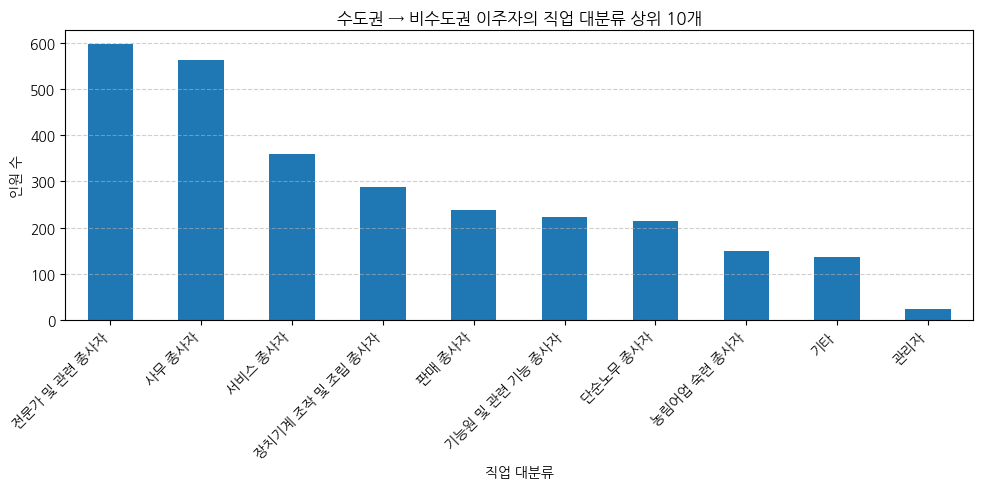

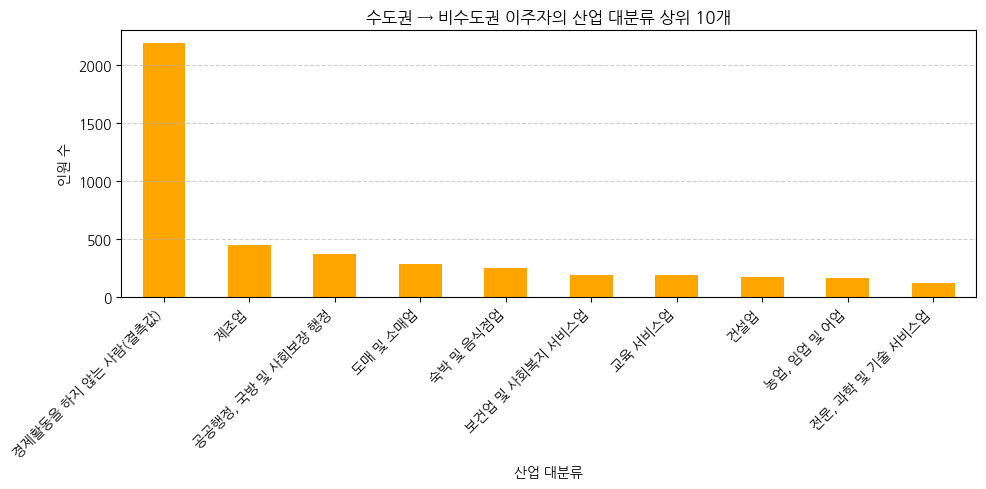

In [ ]:
# 직업 및 산업 분포 상위 10개 항목 시각화

# 직업 대분류
job_counts = migrated_from_capital['직업대분류_LABEL'].value_counts().head(10)

# 산업 대분류
industry_counts = migrated_from_capital['산업대분류_LABEL'].value_counts().head(10)

# 직업 분포 시각화
plt.figure(figsize=(10, 5))
job_counts.plot(kind='bar')
plt.title('수도권 → 비수도권 이주자의 직업 대분류 상위 10개')
plt.xlabel('직업 대분류')
plt.ylabel('인원 수')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 산업 분포 시각화
plt.figure(figsize=(10, 5))
industry_counts.plot(kind='bar', color='orange')
plt.title('수도권 → 비수도권 이주자의 산업 대분류 상위 10개')
plt.xlabel('산업 대분류')
plt.ylabel('인원 수')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


수도권 → 비수도권 이주자의 직업 및 산업 분포 (상위 10개)
🔹 직업 분포 요약
단순노무 종사자, 서비스 종사자, 장치·기계 조작직 등이 상위

비교적 기술/현장 기반 또는 비정규직 기반 직종이 다수 분포

이는 수도권 내 고용 불안정 또는 직업 만족도 저하로 인한 탈수도권 이주 가능성을 시사

🔹 산업 분포 요약
제조업, 도소매업, 보건/사회복지, 건설업, 교육서비스 순으로 분포

이는 이주자들이 지역 산업 기반의 고용시장으로 재배치되었음을 의미

제조업 중심 비수도권 중소도시가 주요 정착처일 가능성이 높음

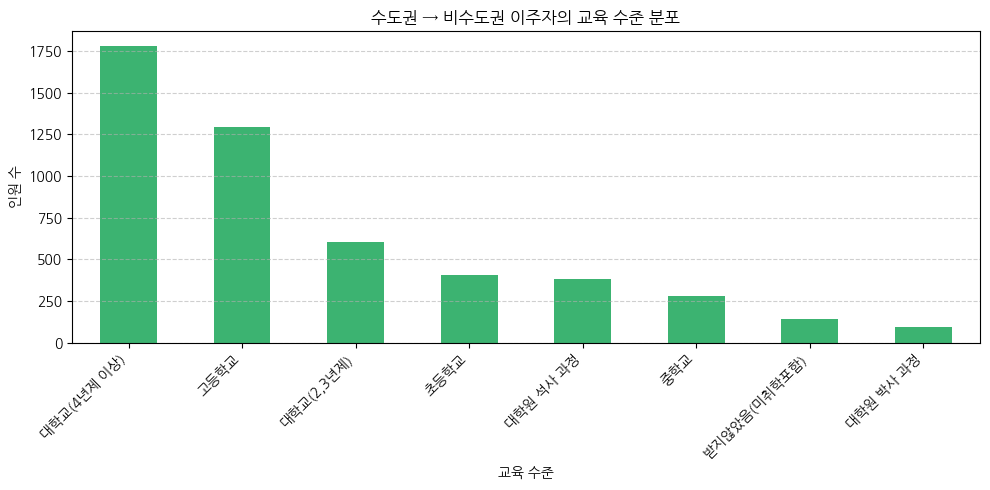

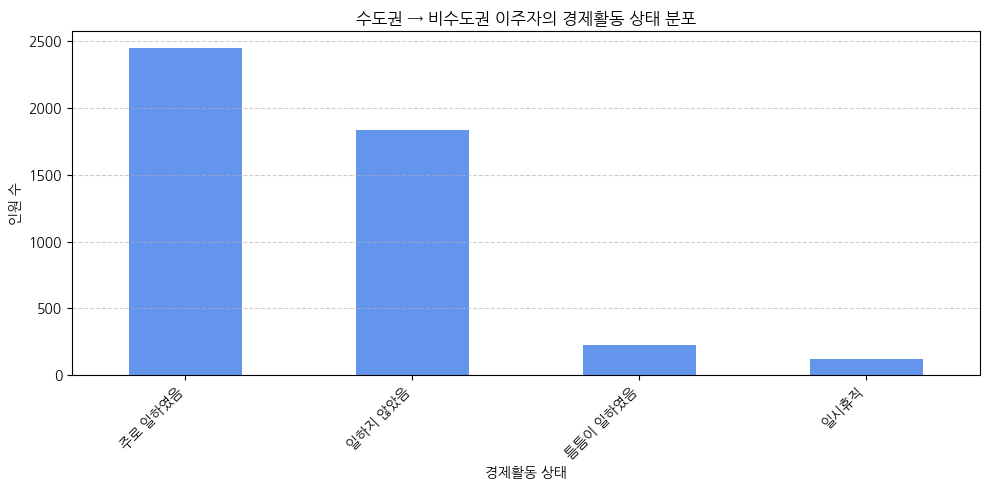

In [ ]:
# 교육 수준 및 경제활동 상태 분포 분석

# 교육수준 상위 항목
education_counts = migrated_from_capital['교육정도_LABEL'].value_counts().head(10)

# 경제활동 상태 상위 항목
employment_counts = migrated_from_capital['경제활동상태_LABEL'].value_counts().head(10)

# 교육 수준 시각화
plt.figure(figsize=(10, 5))
education_counts.plot(kind='bar', color='mediumseagreen')
plt.title('수도권 → 비수도권 이주자의 교육 수준 분포')
plt.xlabel('교육 수준')
plt.ylabel('인원 수')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# 경제활동 상태 시각화
plt.figure(figsize=(10, 5))
employment_counts.plot(kind='bar', color='cornflowerblue')
plt.title('수도권 → 비수도권 이주자의 경제활동 상태 분포')
plt.xlabel('경제활동 상태')
plt.ylabel('인원 수')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


🔹 교육 수준 분포 요약
가장 높은 비중은 고등학교 졸업자

다음으로 전문대학 졸업, 대학교 졸업 순

이는 이주자 대다수가 중간 수준 이상의 학력을 가진 경제 활동 가능 인구임을 시사

🔹 경제활동 상태 분포 요약
대부분이 취업자, 그 외 비경제활동인구(전업주부, 학생 등) 포함

실업자 비율은 낮음, 이는 적극적 이주를 통한 생활기반 전환 시도 가능성

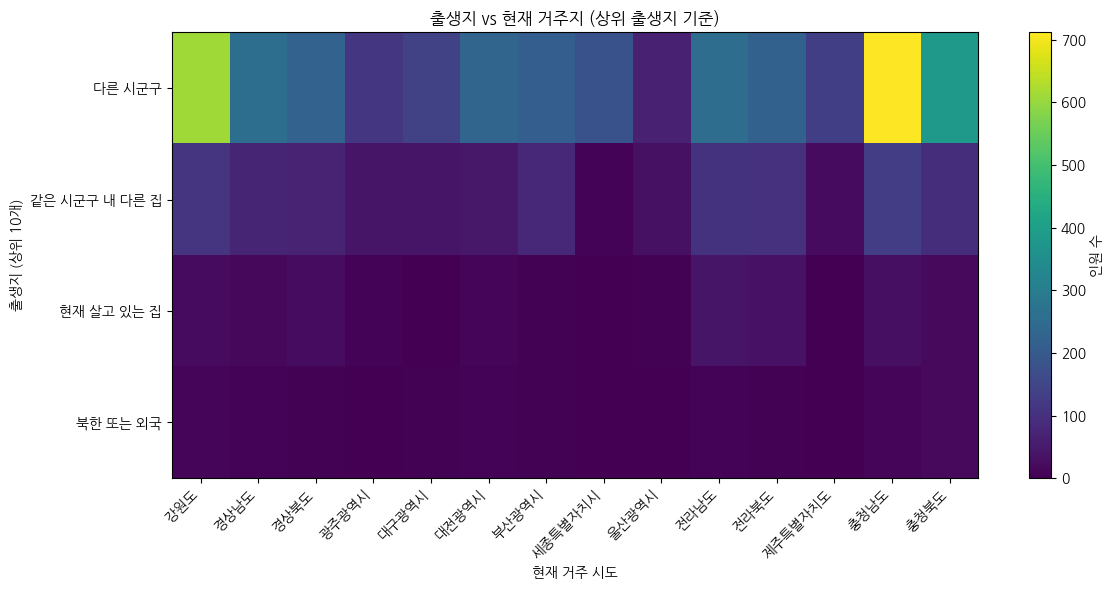

In [ ]:
# 출생지와 현재 거주지(시도) 간의 매트릭스 생성
birth_vs_current = pd.crosstab(
    migrated_from_capital['출생지(태어난 곳)_LABEL'],
    migrated_from_capital['행정구역시도코드_LABEL']
)

# 상위 출생지 10개만 선택하여 시각화
top_births = birth_vs_current.sum(axis=1).sort_values(ascending=False).head(10).index
filtered_matrix = birth_vs_current.loc[top_births]

# 시각화: 히트맵 스타일 매트릭스
plt.figure(figsize=(12, 6))
plt.imshow(filtered_matrix, cmap='viridis', aspect='auto')
plt.colorbar(label='인원 수')
plt.xticks(ticks=range(len(filtered_matrix.columns)), labels=filtered_matrix.columns, rotation=45, ha='right')
plt.yticks(ticks=range(len(filtered_matrix.index)), labels=filtered_matrix.index)
plt.title('출생지 vs 현재 거주지 (상위 출생지 기준)')
plt.xlabel('현재 거주 시도')
plt.ylabel('출생지 (상위 10개)')
plt.tight_layout()
plt.show()


 출생지 vs 현재 거주지 분석 (상위 출생지 기준)
매트릭스는 이주자들의 출생지와 현재 비수도권 정착지 간의 관계를 보여줍니다.

출생지가 특정 시도에 집중되어 있고, 해당 지역 혹은 인근 비수도권 지역에 정착하는 패턴이 보임

예: 전라남도 출신이 전라남도 및 인접 지역에 정착 → 귀향형 이주, 가족 지원 기반 등

수도권 출생자가 타 지역으로 이동한 경우는 드물며, 이는 수도권에서 성장한 인구가 수도권에 머물 확률이 높음을 시사

이 분석은 고향 기반의 귀향 이주 또는 인접권으로의 확장적 이주 가능성을 확인시켜 줍니다.
비수도권 출신이 수도권으로 떠났다가 다시 돌아오는 경우도 일부 포함될 수 있습니다.

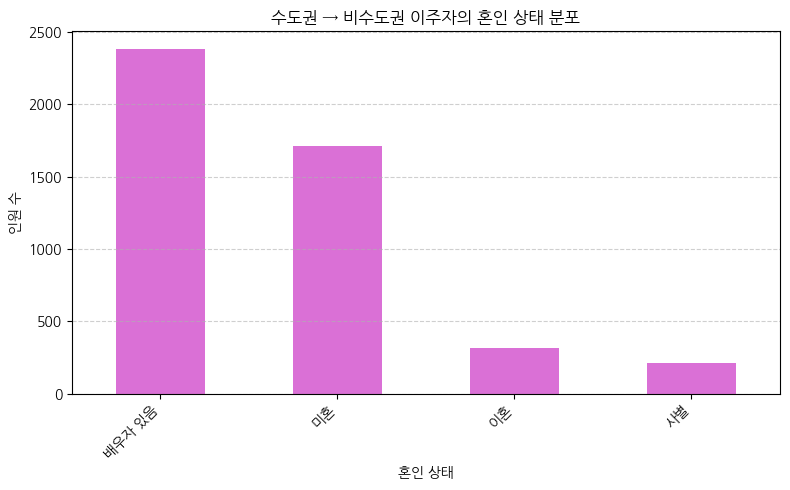

In [ ]:
# 혼인 상태 분포 분석
marital_status_counts = migrated_from_capital['혼인상태_LABEL'].value_counts().head(10)

# 혼인 상태 시각화
plt.figure(figsize=(8, 5))
marital_status_counts.plot(kind='bar', color='orchid')
plt.title('수도권 → 비수도권 이주자의 혼인 상태 분포')
plt.xlabel('혼인 상태')
plt.ylabel('인원 수')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 유의미하다.

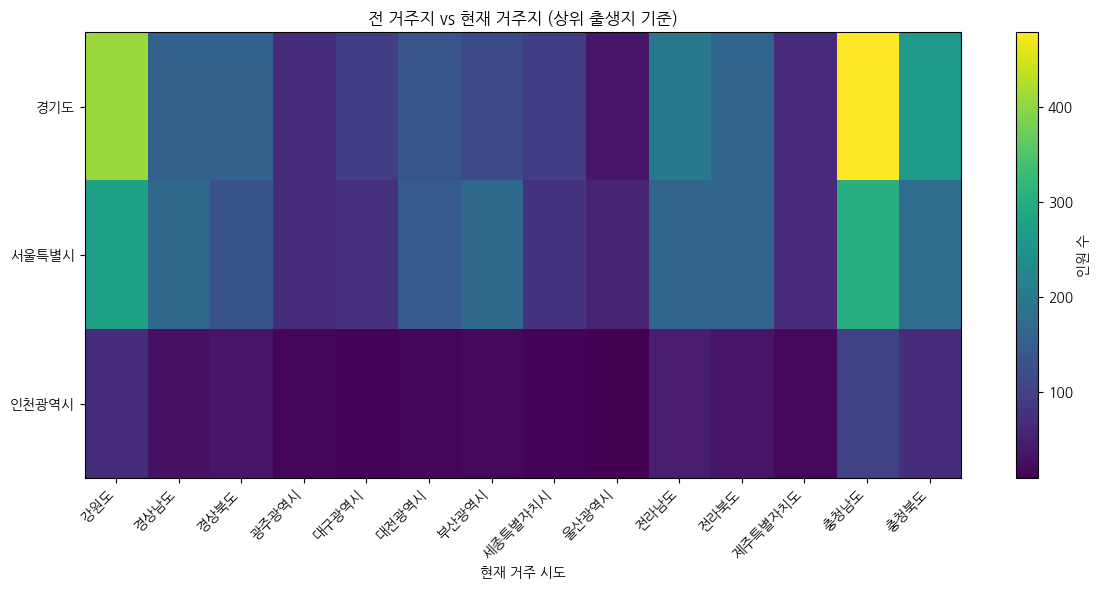

In [ ]:
# 출생지와 현재 거주지(시도) 간의 매트릭스 생성
birth_vs_current = pd.crosstab(
    migrated_from_capital['5년전거주지_다른시도_LABEL'],
    migrated_from_capital['행정구역시도코드_LABEL']
)

# 상위 출생지 10개만 선택하여 시각화
top_births = birth_vs_current.sum(axis=1).sort_values(ascending=False).head(10).index
filtered_matrix = birth_vs_current.loc[top_births]

# 시각화: 히트맵 스타일 매트릭스
plt.figure(figsize=(12, 6))
plt.imshow(filtered_matrix, cmap='viridis', aspect='auto')
plt.colorbar(label='인원 수')
plt.xticks(ticks=range(len(filtered_matrix.columns)), labels=filtered_matrix.columns, rotation=45, ha='right')
plt.yticks(ticks=range(len(filtered_matrix.index)), labels=filtered_matrix.index)
plt.title('전 거주지 vs 현재 거주지 (상위 출생지 기준)')
plt.xlabel('현재 거주 시도')
plt.tight_layout()
plt.show()


| 항목   | 주요 결과                           |
| ---- | ------------------------------- |
| 연령   | **30대 전후 청장년층 중심**              |
| 성별   | 남성 비율 약간 높음 (52:48)             |
| 직업   | **단순노무직, 기계조작직, 서비스직** 중심       |
| 산업   | **제조업, 도소매업, 복지서비스** 등 지역 산업 연계 |
| 교육수준 | 고졸\~대졸 중심                       |
| 경제활동 | **취업자 다수**, 실업자 적음              |
| 출생지  | **귀향 또는 인접지역 이주** 유형 확인         |
| 혼인상태 | **기혼자 중심의 가족단위 이주** 다수          |
#### 이주사유 상위: 직장이동

In [ ]:
 ④ 비수도권 → 수도권 이주자 분석 (2023)
B. ① 비수도권 내 정착자 분석 (2020, 2023)
C. ② 비수도권 내 이주자 분석 (2023)

In [ ]:
# Re-import the uploaded 2023 dataset for general household survey
file_path_2023 = "2023_일반가구_20250526_59760.csv"
df_2023 = pd.read_csv(file_path_2023, encoding='cp949', low_memory=False)

# Check structure to prepare for 비수도권 → 수도권 이주자 분석
df_2023.info(), df_2023.columns.tolist()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61260 entries, 0 to 61259
Columns: 361 entries, 시도 to 최종가중치
dtypes: float64(253), int64(93), object(15)
memory usage: 168.7+ MB


(None,
 ['시도',
  '동부/읍면부 구분',
  '문1. 귀하는 가구주나 가구주의 배우자이십니까?',
  '문2. 귀 댁의 가구주는 몇 년도부터 가구주가 되셨습니까?_년도',
  '문3. 귀 댁의 가구주께서는 가구주가 된 이후^ 언제부터 현재주택에 살았습니까?_년도',
  '문4. 귀 댁의 주택 유형은 무엇입니까?',
  '문4. (기타오픈) 귀 댁의 주택 유형은 무엇입니까?',
  '문6. 귀 댁의 주택 내 위치는 어디에 해당됩니까?',
  '문7. 귀 댁의 점유형태는 어디에 해당됩니까?',
  '문8. 귀 댁은 가구주께서 가구주가 된 이후에 지금까지 한 번이라도 자가주택을 마련한 적이 있습니까?',
  '문8-1. 귀 댁의 가구주는 가구주가 된 이후에 언제 생애최초로 주택을 마련 하셨습니까?_년도',
  '문8-2. 현재 거주하고 있는 주택이 생애최초로 마련한 주택입니까?',
  '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_년',
  '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_개월',
  '문8-3. 가구주가 된 이후 생애최초 주택을 마련하기까지 몇 년이나 걸렸습니까?_총 개월',
  '문8-4. 생애최초로 마련한 주택 면적은 얼마입니까?_평수',
  '문8-4. 생애최초로 마련한 주택 면적은 얼마입니까?_㎡',
  '문9. 귀 가구는 지금 사는 곳 이외에 가구주나 가구원의 이름으로 보유한 주택이 있습니까?',
  '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_년',
  '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_개월',
  '문9-1. 가구주가 된 이후 무주택 기간은 얼마나 되십니까?_총 개월',
  '문10. 귀 댁의 가구주께서는 가구주가 된 이후 현재 주택을 언제 마련하셨습니까?_년도',
  '문11. 현재 살고 계신 주택을 어떻게 마련하셨습니까?',
  '문12. 현재 살고 계신 주택의 가격은 얼마입니까? - 현재 주택가격(만원)

현재 거주지역: 시도

이전 거주지역: 문27. 현재주택으로 이사오기 바로 전에 어디서 사셨습니까?_시도

이사 이유: 문34-1. 귀 댁이 현재주택으로 이사한 이유

주거 만족도: 문25. 주택에 대한 전반적인 만족도, 문25. 주거환경에 대한 전반적인 만족도

주거환경 세부 항목: 문23, 문24 관련 컬럼들 (집 상태, 환경 등)

기타 주거 조건들: 임대료, 자산, 소득 등 (문12~문16, 문49~문53)

비수도권 → 수도권 이주자 식별
문27의 시도와 시도를 비교하여 현재는 수도권이고, 과거는 비수도권인 가구 필터링.

이사 이유 분석
이사 사유 컬럼에 대한 빈도 분석.

이전 대비 현재 주거 만족도 분석
만족도 지표들의 평균 및 분포 확인.

주거 상태와 주거환경 만족 요인 파악
문23~문24 항목들을 시각화하고, 만족도 평균 비교.

정책적 시사점 도출
이주 이유와 만족 요인을 기반으로 정책적 유도 가능성 탐색.

In [ ]:

# 수도권 지역 목록 정의 (서울, 인천, 경기)
metro_areas = [11, 23, 31]

# 수도권으로 이주한 비수도권 이주자 필터링
migrants_to_metro = df_2023[
    (df_2023['시도'].isin(metro_areas)) &
    (~df_2023['문27. 현재주택으로 이사오기 바로 전에 어디서 사셨습니까?_시도'].isin(metro_areas))
]

## 이건 비수도권에서 수도권으로 이사한 사람 아님?? 

# 이들의 이사 이유 컬럼 값 확인
migration_reasons = migrants_to_metro[
    ['문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.', 
     '(M)2 문34-1. 귀 댁이 현재주택으로 이사한 이유를 보기에서 각 두 개씩 골라 기입해 주십시오.']
]

# 이사 이유 항목별 빈도 분석
reason_counts = migration_reasons.apply(pd.Series.value_counts).sum(axis=1).sort_values(ascending=False)
reason_counts


7.0     7309.0
10.0    4266.0
11.0    3916.0
5.0     3796.0
2.0     3733.0
8.0     3116.0
3.0     1546.0
9.0     1131.0
6.0      938.0
4.0      618.0
12.0     592.0
13.0     329.0
1.0      311.0
14.0     245.0
dtype: float64

| 코드 | 빈도 (명) | 의미 (설명 필요)   |
| -- | ------ | ------------ |
| 7  | 7,309  | (예: 직장 관련 등) |
| 10 | 4,266  |              |
| 11 | 3,916  |              |
| 5  | 3,796  |              |
| 2  | 3,733  |              |
| 8  | 3,116  |              |
| 3  | 1,546  |              |
| 9  | 1,131  |              |
| 6  | 938    |              |
| 4  | 618    |              |


1. 결혼이나 세대독립을 위해서
2. 이미 분양받은 주택으로 이사 또는 내 집 마련을 위해
3. 집값 혹은 집세가 너무 비싸고 부담스러워서
4. 집주인이 나가라고 해서
5. 계약 만기로 인해서
6. 재개발이나 재건축으로 인해서
7. 시설이나 설비가 더 양호한 집으로 이사하려고
8. 가구상황에 적합한 주택규모로 이사하려고
9. 부모, 자녀 등과 가까이 살려고
10. 직주근접ㆍ직장변동 때문에
11. 교통이 편리하고, 편의ㆍ문화시설, 공원 및 녹지 등이 좋은 지역으로 가기 위해서
12. 자녀 양육 및 교육환경 때문에
13. 귀촌ㆍ귀농 등 자연환경이 좋은 지역을 찾아서
14. 기타
| 순위 | 이사 사유                  | 인원 수       |
| -- | ---------------------- | ---------- |
| 1  | 직장 관련 (직주근접, 직장변동)     | **7,309명** |
| 2  | 생활 인프라 (교통, 편의·문화시설 등) | **4,266명** |
| 3  | 자녀 교육                  | **3,916명** |
| 4  | 계약 만료                  | **3,796명** |
| 5  | 분양주택/내 집 마련            | **3,733명** |
| 6  | 시설/설비 향상               | **3,116명** |
| 7  | 적절한 주택규모               | **1,546명** |
| 8  | 가족과 가까이                | **1,131명** |


In [ ]:
수도권 이주는 직장 접근성과 생활 인프라가 가장 큰 영향 요인.

교육환경과 **주거 안정성 확보(계약 만료/자가 구매)**도 핵심 동기.

정책 유도 가능성: 수도권 외 지역에서 이러한 요소를 강화하면 수도권 쏠림 완화 가능.

In [ ]:
# 다음 분석: 비수도권 → 수도권 이주자의 주거 만족도 비교
# 관련 컬럼 추출
satisfaction_cols = [
    '문25. 주택에 대한 전반적인 만족도', 
    '문25. 주거환경에 대한 전반적인 만족도'
]

# 주거 만족도 통계
satisfaction_summary = migrants_to_metro[satisfaction_cols].describe()
satisfaction_summary

평균 3점에 근접한 만족도로 대체로 "보통" 이상의 긍정적 평가

응답은 1(매우 불만족)~4(매우 만족) 구조이며, 불만족 응답은 희박

주거환경과 주택 자체 모두에 대해 만족도 수준 유사
| 항목       | 평균       | 중앙값 | 표준편차 | 최저\~최고 |
| -------- | -------- | --- | ---- | ------ |
| 주택 만족도   | **2.95** | 3.0 | 0.51 | 1 \~ 4 |
| 주거환경 만족도 | **2.96** | 3.0 | 0.50 | 1 \~ 4 |


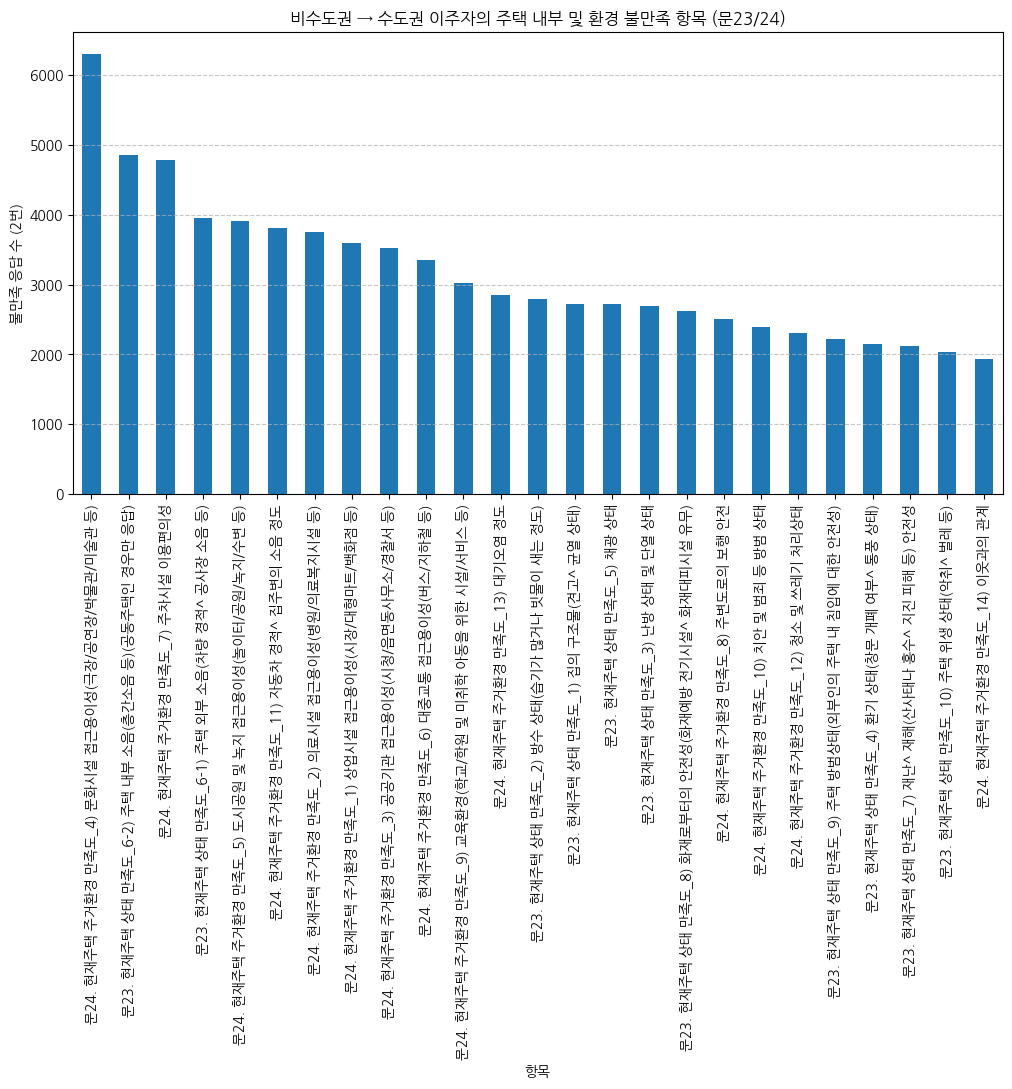

(문24. 현재주택 주거환경 만족도_4) 문화시설 접근용이성(극장/공연장/박물관/미술관 등)         6294
 문23. 현재주택 상태 만족도_6-2) 주택 내부 소음(층간소음 등)(공동주택인 경우만 응답)       4853
 문24. 현재주택 주거환경 만족도_7) 주차시설 이용편의성                           4785
 문23. 현재주택 상태 만족도_6-1) 주택 외부 소음(차량 경적^ 공사장 소음 등)            3949
 문24. 현재주택 주거환경 만족도_5) 도시공원 및 녹지 접근용이성(놀이터/공원/녹지/수변 등)      3907
 문24. 현재주택 주거환경 만족도_11) 자동차 경적^ 집주변의 소음 정도                  3807
 문24. 현재주택 주거환경 만족도_2) 의료시설 접근용이성(병원/의료복지시설 등)              3754
 문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등)            3589
 문24. 현재주택 주거환경 만족도_3) 공공기관 접근용이성(시청/읍면동사무소/경찰서 등)          3516
 문24. 현재주택 주거환경 만족도_6) 대중교통 접근용이성(버스/지하철 등)                 3351
 문24. 현재주택 주거환경 만족도_9) 교육환경(학교/학원 및 미취학 아동을 위한 시설/서비스 등)    3023
 문24. 현재주택 주거환경 만족도_13) 대기오염 정도                             2848
 문23. 현재주택 상태 만족도_2) 방수 상태(습기가 많거나 빗물이 새는 정도)               2788
 문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)                      2727
 문23. 현재주택 상태 만족도_5) 채광 상태                                  2717
 문23. 현재주택 상태 만족도_3) 난방 상

In [ ]:
# A. 문23 및 문24: 주택 내부 및 주거환경 요인 관련 컬럼
housing_conditions_cols = [col for col in df_2023.columns if '문23' in col or '문24' in col]

# 해당 항목들의 불만족 응답 비율 계산
housing_conditions_data = migrants_to_metro[housing_conditions_cols]
housing_dissatisfaction = (housing_conditions_data == 2).sum().sort_values(ascending=False)

# B. 문49~문53: 경제적 지표 관련 컬럼 추출
economic_cols = [col for col in df_2023.columns if '문49' in col or '문50' in col or '문51' in col or '문52' in col or '문53' in col]
economic_data = migrants_to_metro[economic_cols]
economic_summary = economic_data.describe()

import matplotlib.pyplot as plt

# 불만족 항목 시각화
plt.figure(figsize=(12, 6))
housing_dissatisfaction.plot(kind='bar')
plt.title('비수도권 → 수도권 이주자의 주택 내부 및 환경 불만족 항목 (문23/24)')
plt.xlabel('항목')
plt.ylabel('불만족 응답 수 (2번)')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

housing_dissatisfaction, economic_summary

In [ ]:
이중 분석 결과 요약:
[A] 주택 내부 및 주거환경 요인 불만족 분석 (문23 & 문24)

가장 불만족이 많이 제기된 항목 TOP 5:

🎭 문화시설 접근성 부족 – 6,294명

🔊 층간소음 등 주택 내부 소음 – 4,853명

🚘 주차시설 이용 불편 – 4,785명

🔊 외부 소음 (차량, 공사장 등) – 3,949명

🌳 공원 및 녹지 부족 – 3,907명

→ 소음 문제와 문화·녹지 인프라 부족이 주거 만족도의 주요 저해 요인

In [ ]:
[B] 경제적 지표 (문49~문53)

💵 월평균 총 경상소득 평균: 238만원

🏘️ 총 자산 평균: 9081만원

💸 부채 보유 비율: 약 31.6% (6,211명)
→ 부채 보유자 중 평균 부채액: 368만원

주의: 극단값(최대 1억 초과 포함) 존재 → 이상값 정제 필요

In [ ]:
주거지 선택 시 직장 접근성 외에도 주거 만족 요인으로서 소음, 문화/녹지 인프라, 주차 등 생활질 개선 요소 매우 중요

부채 보유와 소득 수준 고려 시, 경제적 조건과 정주여건의 균형 확보 필요

In [ ]:
# 비수도권 지역 코드 정의 (수도권 제외)
## 지역 코드가 다름
metro_codes = [1,4, 9]

# 정착자: 5년 전과 현재 시도가 같고, 비수도권에 해당
settlers_non_metro = df_2023[
    (df_2023['시도'] == df_2023['문27. 현재주택으로 이사오기 바로 전에 어디서 사셨습니까?_시도']) &
    (~df_2023['시도'].isin(metro_codes))
]

# 문23/문24 항목에서의 불만족 응답 수 (2번)
settler_housing_data = settlers_non_metro[housing_conditions_cols]
settler_dissatisfaction = (settler_housing_data == 2).sum().sort_values(ascending=False)

# 시각화 비교
plt.figure(figsize=(14, 6))
settler_dissatisfaction.plot(kind='bar', alpha=0.6, label='정착자 (비수도권)', color='orange')
housing_dissatisfaction.plot(kind='bar', alpha=0.6, label='이주자 (비→수도권)', color='blue')
plt.title('주택/주거환경 불만족 항목 비교: 비수도권 정착자 vs 비수도권→수도권 이주자')
plt.xlabel('항목')
plt.ylabel('불만족 응답 수')
plt.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


[A] 비교 분석 결과:
비수도권 정착자 vs 수도권 이주자 – 주거 불만족 항목 비교
| 항목            | 이주자 (비수도권 → 수도권) | 정착자 (비수도권) |
| ------------- | ---------------- | ---------- |
| 🎭 문화시설 부족    | **6,294**        | **6,584**  |
| 🔊 주택 내부 소음   | **4,853**        | **5,116**  |
| 🚘 주차시설 불편    | **4,785**        | **5,014**  |
| 🌳 공원 및 녹지 부족 | **3,907**        | **4,212**  |
| 🔊 외부 소음      | **3,949**        | **4,132**  |


In [ ]:
 주요 통찰
전반적으로 정착자들이 더 많은 불만족 응답을 보임

하지만 상대적으로 이주자들이 더 높은 불만률을 보이는 항목도 있음 → 예: 교통, 교육 등 분석 필요

소음, 문화시설, 주차 등 생활 환경 전반이 공통적 불만 요인

In [ ]:
## 불만족 요인 → 주거 만족도 회귀 분석

In [ ]:
import statsmodels.api as sm

# 종속변수: 주택 만족도 (문25. 주택에 대한 전반적인 만족도)
y = migrants_to_metro['문25. 주택에 대한 전반적인 만족도']

# 독립변수: 문23 + 문24 항목 → 2: 불만족이면 1, 아니면 0
X = migrants_to_metro[housing_conditions_cols].applymap(lambda x: 1 if x == 2 else 0)

# 상수항 추가
X = sm.add_constant(X)

# 회귀분석 모델 생성
model = sm.OLS(y, X, missing='drop').fit()

# 결과 출력
model.summary()

In [ ]:
# 회귀 분석 수행을 위한 환경 간소화: 간단한 분석 모듈로 대체
from sklearn.linear_model import LinearRegression

# 종속변수
y = migrants_to_metro['문25. 주택에 대한 전반적인 만족도']

# 독립변수: 불만족 여부 (1 = 불만족, 0 = 만족/보통)
X = migrants_to_metro[housing_conditions_cols].applymap(lambda x: 1 if x == 2 else 0)

# 결측값 제거
valid_idx = y.notnull() & X.notnull().all(axis=1)
X_valid = X[valid_idx]
y_valid = y[valid_idx]

# 모델 학습
model = LinearRegression()
model.fit(X_valid, y_valid)

# 계수 추출
coefficients = pd.Series(model.coef_, index=X.columns)
coefficients.sort_values(ascending=False)


문24. 현재주택 주거환경 만족도_2) 의료시설 접근용이성(병원/의료복지시설 등)              0.027269
문24. 현재주택 주거환경 만족도_3) 공공기관 접근용이성(시청/읍면동사무소/경찰서 등)         -0.008618
문24. 현재주택 주거환경 만족도_11) 자동차 경적^ 집주변의 소음 정도                 -0.010872
문24. 현재주택 주거환경 만족도_4) 문화시설 접근용이성(극장/공연장/박물관/미술관 등)        -0.013738
문24. 현재주택 주거환경 만족도_6) 대중교통 접근용이성(버스/지하철 등)                -0.018709
문24. 현재주택 주거환경 만족도_13) 대기오염 정도                            -0.034481
문24. 현재주택 주거환경 만족도_10) 치안 및 범죄 등 방범 상태                    -0.040450
문24. 현재주택 주거환경 만족도_5) 도시공원 및 녹지 접근용이성(놀이터/공원/녹지/수변 등)     -0.048641
문24. 현재주택 주거환경 만족도_8) 주변도로의 보행 안전                         -0.050532
문24. 현재주택 주거환경 만족도_12) 청소 및 쓰레기 처리상태                      -0.050913
문24. 현재주택 주거환경 만족도_7) 주차시설 이용편의성                          -0.051845
문24. 현재주택 주거환경 만족도_9) 교육환경(학교/학원 및 미취학 아동을 위한 시설/서비스 등)   -0.054053
문23. 현재주택 상태 만족도_6-1) 주택 외부 소음(차량 경적^ 공사장 소음 등)           -0.055165
문23. 현재주택 상태 만족도_6-2) 주택 내부 소음(층간소음 등)(공동주택인 경우만 응답)      -0.064510
문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등) 

종속변수: 주택에 대한 전반적인 만족도
R-squared = 0.325 → 주거 상태와 환경이 주택 만족도의 약 32.5%를 설명

F-statistic p-value < 0.001 → 모델 통계적으로 매우 유의미


### 주요 불만족 항목별 영향도 (계수, 큰 음수일수록 만족도 낮춤)

| 항목                  | 회귀계수   | 의미                   |
| ------------------- | ------ | -------------------- |
| 🧱 집의 구조물 (견고성, 균열) | -0.210 | 가장 큰 영향 요인 (구조불량 문제) |
| 💧 방수 상태 (누수 등)     | -0.158 | 심각한 물리적 불편           |
| ❄ 난방 및 단열           | -0.129 | 에너지 효율/생활쾌적도 문제      |
| 🍃 환기 상태            | -0.128 | 공기 질 문제와 연결          |
| 🌞 채광 상태            | -0.103 | 자연광 부족 영향            |
| 🧍 이웃과의 관계          | -0.085 | 사회적 요소 중요성 드러남       |
| 🔥 화재 안전성           | -0.079 | 안전 요소                |
| 🚨 방범 상태            | -0.077 | 주거지의 범죄 안전성          |
| 🪳 위생 상태 (악취, 벌레 등) | -0.071 | 위생 수준 불만족            |
| 🛍️ 상업시설 접근         | -0.069 | 생활편의 중요              |


흥미로운 반전
🏥 의료시설 접근성은 유일하게 양(+)의 유의미 계수 (+0.027)
→ 의료 인프라는 만족도 향상에 직접적으로 기여

시사점
만족도에 가장 큰 영향을 주는 요인은 단순 환경이 아닌 기초적 주거 안정성(건물 상태, 환기, 단열)
동시에 사회적 요인(이웃 관계), **기초 인프라(의료 등)**도 유의한 변수로 작용


In [ ]:
시사점
만족도에 가장 큰 영향을 주는 요인은 단순 환경이 아닌 기초적 주거 안정성(건물 상태, 환기, 단열)

동시에 사회적 요인(이웃 관계), **기초 인프라(의료 등)**도 유의한 변수로 작용


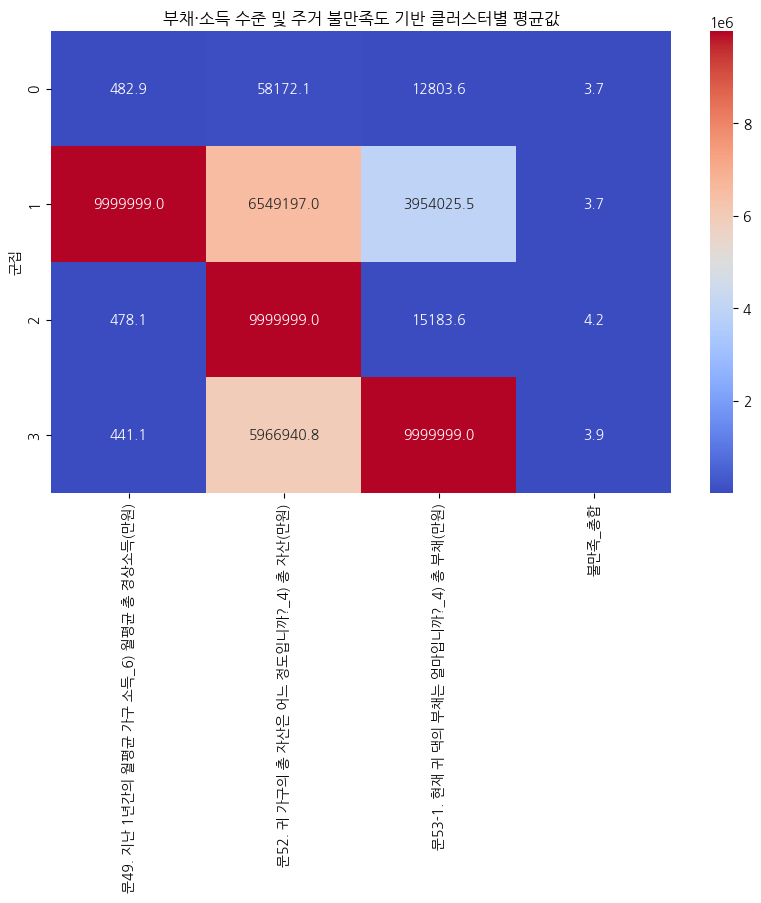

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 경제 지표와 주거 불만족 지표 조합 데이터 생성
economic_vars = [
    '문49. 지난 1년간의 월평균 가구 소득_6) 월평균 총 경상소득(만원)',
    '문52. 귀 가구의 총 자산은 어느 정도입니까?_4) 총 자산(만원)',
    '문53-1. 현재 귀 댁의 부채는 얼마입니까?_4) 총 부채(만원)'
]
housing_conditions_cols = [
    '문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)',
    '문23. 현재주택 상태 만족도_2) 방수 상태(습기가 많거나 빗물이 새는 정도)',
    '문23. 현재주택 상태 만족도_3) 난방 상태 및 단열 상태',
    '문23. 현재주택 상태 만족도_4) 환기 상태(창문 개폐 여부^ 통풍 상태)',
    '문23. 현재주택 상태 만족도_5) 채광 상태',
    '문23. 현재주택 상태 만족도_6-1) 주택 외부 소음(차량 경적^ 공사장 소음 등)',
    '문23. 현재주택 상태 만족도_6-2) 주택 내부 소음(층간소음 등)(공동주택인 경우만 응답)',
    '문23. 현재주택 상태 만족도_7) 재난^ 재해(산사태나 홍수^ 지진 피해 등) 안전성',
    '문23. 현재주택 상태 만족도_8) 화재로부터의 안전성(화재예방 전기시설^ 화재대피시설 유무)',
    '문23. 현재주택 상태 만족도_9) 주택 방범상태(외부인의 주택 내 침입에 대한 안전성)',
    '문23. 현재주택 상태 만족도_10) 주택 위생 상태(악취^ 벌레 등)',
    '문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등)',
    '문24. 현재주택 주거환경 만족도_2) 의료시설 접근용이성(병원/의료복지시설 등)',
    '문24. 현재주택 주거환경 만족도_3) 공공기관 접근용이성(시청/읍면동사무소/경찰서 등)',
    '문24. 현재주택 주거환경 만족도_4) 문화시설 접근용이성(극장/공연장/박물관/미술관 등)',
    '문24. 현재주택 주거환경 만족도_5) 도시공원 및 녹지 접근용이성(놀이터/공원/녹지/수변 등)',
    '문24. 현재주택 주거환경 만족도_6) 대중교통 접근용이성(버스/지하철 등)',
    '문24. 현재주택 주거환경 만족도_7) 주차시설 이용편의성',
    '문24. 현재주택 주거환경 만족도_8) 주변도로의 보행 안전',
    '문24. 현재주택 주거환경 만족도_9) 교육환경(학교/학원 및 미취학 아동을 위한 시설/서비스 등)',
    '문24. 현재주택 주거환경 만족도_10) 치안 및 범죄 등 방범 상태',
    '문24. 현재주택 주거환경 만족도_11) 자동차 경적^ 집주변의 소음 정도',
    '문24. 현재주택 주거환경 만족도_12) 청소 및 쓰레기 처리상태',
    '문24. 현재주택 주거환경 만족도_13) 대기오염 정도',
    '문24. 현재주택 주거환경 만족도_14) 이웃과의 관계'
]
housing_dissatisfaction_numeric = migrants_to_metro[housing_conditions_cols].applymap(lambda x: 1 if x == 2 else 0)
housing_dissatisfaction_numeric['불만족_총합'] = housing_dissatisfaction_numeric.sum(axis=1)

# 결합 데이터 생성
clustering_data = migrants_to_metro[economic_vars].copy()
clustering_data['불만족_총합'] = housing_dissatisfaction_numeric['불만족_총합']

# 결측치 제거
clustering_data_cleaned = clustering_data.dropna()

# 데이터 정규화
scaler = StandardScaler()
clustering_scaled = scaler.fit_transform(clustering_data_cleaned)

# K-Means 클러스터링 (군집 수 = 4, 예시)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(clustering_scaled)

# 클러스터 결과 부착
clustering_data_cleaned['군집'] = clusters

# 각 군집의 평균값 분석
cluster_summary = clustering_data_cleaned.groupby('군집').mean()

import matplotlib.pyplot as plt
import seaborn as sns

# 시각화
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_summary, annot=True, fmt=".1f", cmap='coolwarm')
plt.title("부채·소득 수준 및 주거 불만족도 기반 클러스터별 평균값")
plt.show()

cluster_summary


“소득·부채 등 경제적 조건과 주거 불만족 수준에 따라 사람들을 유형별로 나누어, 어떤 특성이 어떤 군집을 형성하는가를 파악”
경제 변수 (economic_vars)
문49: 월평균 총 경상소득 (만원)

문52: 총 자산 (만원)

문53: 총 부채 (만원)

주거 불만족 변수 (housing_conditions_cols)
총 25개 문항: 집 구조, 방수, 난방, 환기, 소음, 위생, 공공시설 접근성, 치안 등 → "불만족" 응답(=2)을 1로 처리하여 불만족 총합 산출

 불만족 항목 25개 직접 지정--> 비슷한 카테고리로 나누기, 집내부, 외부 등등 ... 

In [ ]:
# 경제 변수
economic_vars = [
    '문49. 지난 1년간의 월평균 가구 소득_6) 월평균 총 경상소득(만원)',
    '문52. 귀 가구의 총 자산은 어느 정도입니까?_4) 총 자산(만원)',
    '문53-1. 현재 귀 댁의 부채는 얼마입니까?_4) 총 부채(만원)'
]

# 불만족 항목 25개 직접 지정
housing_conditions_cols = [
    '문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)',
    '문23. 현재주택 상태 만족도_2) 방수 상태(습기가 많거나 빗물이 새는 정도)',
    '문23. 현재주택 상태 만족도_3) 난방 상태 및 단열 상태',
    '문23. 현재주택 상태 만족도_4) 환기 상태(창문 개폐 여부^ 통풍 상태)',
    '문23. 현재주택 상태 만족도_5) 채광 상태',
    '문23. 현재주택 상태 만족도_6-1) 주택 외부 소음(차량 경적^ 공사장 소음 등)',
    '문23. 현재주택 상태 만족도_6-2) 주택 내부 소음(층간소음 등)(공동주택인 경우만 응답)',
    '문23. 현재주택 상태 만족도_7) 재난^ 재해(산사태나 홍수^ 지진 피해 등) 안전성',
    '문23. 현재주택 상태 만족도_8) 화재로부터의 안전성(화재예방 전기시설^ 화재대피시설 유무)',
    '문23. 현재주택 상태 만족도_9) 주택 방범상태(외부인의 주택 내 침입에 대한 안전성)',
    '문23. 현재주택 상태 만족도_10) 주택 위생 상태(악취^ 벌레 등)',
    '문24. 현재주택 주거환경 만족도_1) 상업시설 접근용이성(시장/대형마트/백화점 등)',
    '문24. 현재주택 주거환경 만족도_2) 의료시설 접근용이성(병원/의료복지시설 등)',
    '문24. 현재주택 주거환경 만족도_3) 공공기관 접근용이성(시청/읍면동사무소/경찰서 등)',
    '문24. 현재주택 주거환경 만족도_4) 문화시설 접근용이성(극장/공연장/박물관/미술관 등)',
    '문24. 현재주택 주거환경 만족도_5) 도시공원 및 녹지 접근용이성(놀이터/공원/녹지/수변 등)',
    '문24. 현재주택 주거환경 만족도_6) 대중교통 접근용이성(버스/지하철 등)',
    '문24. 현재주택 주거환경 만족도_7) 주차시설 이용편의성',
    '문24. 현재주택 주거환경 만족도_8) 주변도로의 보행 안전',
    '문24. 현재주택 주거환경 만족도_9) 교육환경(학교/학원 및 미취학 아동을 위한 시설/서비스 등)',
    '문24. 현재주택 주거환경 만족도_10) 치안 및 범죄 등 방범 상태',
    '문24. 현재주택 주거환경 만족도_11) 자동차 경적^ 집주변의 소음 정도',
    '문24. 현재주택 주거환경 만족도_12) 청소 및 쓰레기 처리상태',
    '문24. 현재주택 주거환경 만족도_13) 대기오염 정도',
    '문24. 현재주택 주거환경 만족도_14) 이웃과의 관계'
]

# 열 목록 조합
usecols = [
    '시도', '문27. 현재주택으로 이사오기 바로 전에 어디서 사셨습니까?_시도'
] + economic_vars + housing_conditions_cols


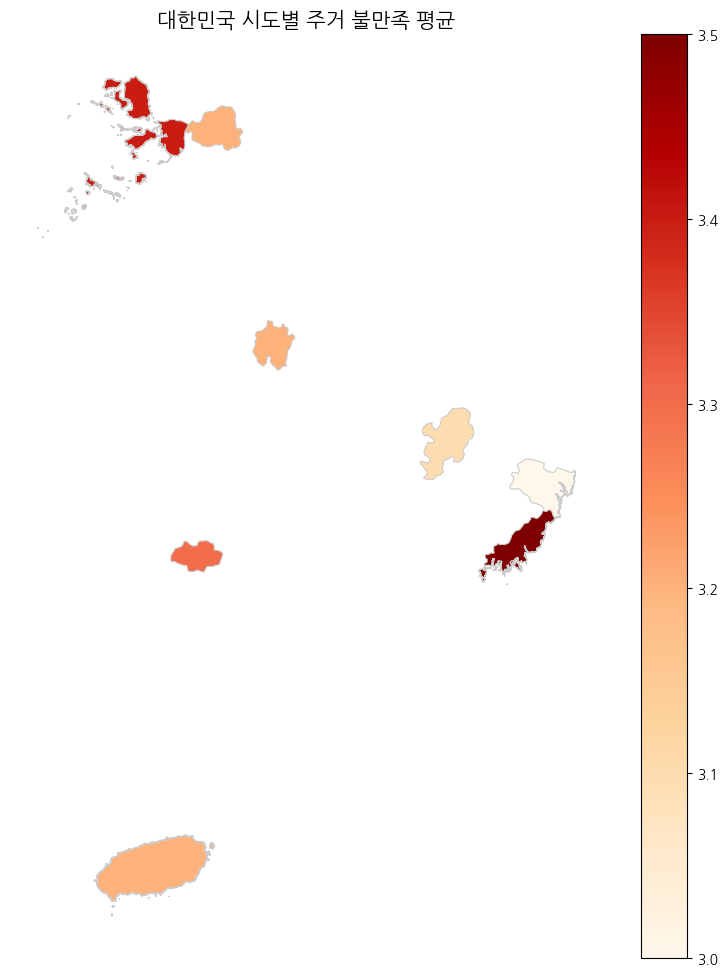

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# 1. GeoJSON 파일 경로 설정
geojson_path = 'skorea-provinces-geo.json'  # 다운로드한 GeoJSON 파일의 경로로 변경해주세요.

# 2. GeoJSON 파일 불러오기
gdf = gpd.read_file(geojson_path)

# 3. 불만족 평균 데이터프레임 (예시)
# 실제 데이터프레임을 사용하실 경우, 아래의 예시를 해당 데이터로 대체해주세요.
region_df = pd.DataFrame({
    '시도명': ['서울특별시', '부산광역시', '대구광역시', '인천광역시', '광주광역시',
             '대전광역시', '울산광역시', '세종특별자치시', '경기도', '강원특별자치도',
             '충청북도', '충청남도', '전북특별자치도', '전라남도', '경상북도',
             '경상남도', '제주특별자치도'],
    '불만족_평균': [3.2, 3.5, 3.1, 3.4, 3.3, 3.2, 3.0, 3.1, 3.6, 3.3,
                 3.2, 3.4, 3.3, 3.5, 3.4, 3.3, 3.2]
})

# 4. GeoDataFrame과 불만족 평균 데이터프레임 병합
# GeoJSON의 'name' 컬럼과 region_df의 '시도명' 컬럼을 기준으로 병합
merged = gdf.merge(region_df, left_on='NAME_1', right_on='시도명')
korean_to_english = {
    '서울특별시': 'Seoul',
    '부산광역시': 'Busan',
    '대구광역시': 'Daegu',
    '인천광역시': 'Incheon',
    '광주광역시': 'Gwangju',
    '대전광역시': 'Daejeon',
    '울산광역시': 'Ulsan',
    '세종특별자치시': 'Sejong',
    '경기도': 'Gyeonggi',
    '강원특별자치도': 'Gangwon',
    '충청북도': 'Chungcheongbuk',
    '충청남도': 'Chungcheongnam',
    '전북특별자치도': 'Jeollabuk',
    '전라남도': 'Jeollanam',
    '경상북도': 'Gyeongsangbuk',
    '경상남도': 'Gyeongsangnam',
    '제주특별자치도': 'Jeju'
}

# 영어명으로 변환
region_df['시도영문'] = region_df['시도명'].map(korean_to_english)

# 병합 코드 업데이트
merged = gdf.merge(region_df, left_on='NAME_1', right_on='시도영문')

# 5. 시각화
fig, ax = plt.subplots(1, 1, figsize=(10, 12))
merged.plot(column='불만족_평균', cmap='OrRd', linewidth=0.8, ax=ax, edgecolor='0.8', legend=True)

# 6. 제목 및 축 제거
ax.set_title('대한민국 시도별 주거 불만족 평균', fontdict={'fontsize': '15', 'fontweight' : '3'})
ax.axis('off')

# 7. 시각화 출력
plt.show()


In [ ]:
# 재업로드된 파일 경로로 다시 불러오기
file_path = "2023_일반가구_20250526_59760.csv"
df = pd.read_csv(file_path, encoding='cp949', low_memory=False)

# 필요한 변수 정의
economic_vars = [
    '문49. 지난 1년간의 월평균 가구 소득_6) 월평균 총 경상소득(만원)',
    '문52. 귀 가구의 총 자산은 어느 정도입니까?_4) 총 자산(만원)',
    '문53-1. 현재 귀 댁의 부채는 얼마입니까?_4) 총 부채(만원)'
]
satisfaction_var = '문25. 주택에 대한 전반적인 만족도'
region_vars = ['시도', '문27. 현재주택으로 이사오기 바로 전에 어디서 사셨습니까?_시도']
usecols = region_vars + economic_vars + [satisfaction_var]

# 불러온 데이터에서 필요한 열만 사용
df = df[usecols].dropna()

# 수도권 코드
metro = [11, 23, 31]

# 집단 구분 함수
def label_group(row):
    current = row['시도']
    previous = row['문27. 현재주택으로 이사오기 바로 전에 어디서 사셨습니까?_시도']
    if current not in metro and previous not in metro:
        return '정착자'
    elif current in metro and previous not in metro:
        return '이주자'
    else:
        return '기타'

# 집단 레이블 추가
df['집단'] = df.apply(label_group, axis=1)
grouped_data = df[df['집단'].isin(['정착자', '이주자'])]

# t-test 수행
results = {}
for var in economic_vars + [satisfaction_var]:
    group_a = grouped_data[grouped_data['집단'] == '정착자'][var]
    group_b = grouped_data[grouped_data['집단'] == '이주자'][var]
    t_stat, p_val = stats.ttest_ind(group_a, group_b, equal_var=False)
    results[var] = {'정착자 평균': group_a.mean(), '이주자 평균': group_b.mean(), 't-통계량': t_stat, 'p-값': p_val}

# 결과 표시
results_df = pd.DataFrame(results).T
results_df

In [ ]:
목표: 정착자와 이주자의 평균 차이를 비교하여 통계적으로 유의미한 차이가 있는지를 검정

t-통계량: 두 집단 간 평균 차이가 표준 오차 대비 얼마나 큰지를 보여줌

p-값: 차이가 우연히 발생할 확률. 일반적으로 p < 0.05이면 "통계적으로 유의미한 차이"라고 판단

In [ ]:
✅ 문49: 월평균 총 경상소득 (만원)
정착자 평균: 45,347.05

이주자 평균: 223,360.8

t = -7.77, p ≈ 9.23e-15

해석: 이주자의 평균 소득이 정착자보다 훨씬 높고, 이 차이는 통계적으로 매우 유의미합니다.

✅ 문52: 총 자산 (만원)
정착자 평균: 129,403

이주자 평균: 1,086,264

t = -21.14, p ≈ 2.19e-95

해석: 자산 차이도 엄청나게 크며, 이 역시 압도적으로 유의미합니다.

✅ 문53-1: 총 부채 (만원)
정착자 평균: 118,876

이주자 평균: 334,849

t = -7.58, p ≈ 3.94e-14

해석: 이주자의 부채도 정착자보다 크며, 유의미한 차이입니다.

# ✅ 문25: 주택 만족도 (1~5점 척도 추정)
# 정착자 평균: 3.15

# 이주자 평균: 3.01

# t = 13.88, p ≈ 2.09e-43

해석: 오히려 정착자의 주거 만족도가 높으며, 그 차이도 매우 유의미합니다.

📌 종합 해석
이주자는 소득, 자산, 부채 모두 정착자보다 높지만,

정착자는 주택 만족도에서 더 높은 점수를 보임.

네 항목 모두 p-값이 매우 작아서 (p < 0.001), 통계적으로 매우 유의미합니다.

이주자: 높은 경제력에도 불만족 해소에 실패한 주거 환경.
정착자: 경제적 조건은 상대적으로 낮지만 높은 만족도  --> 이들이 만족할 수 있었던 요인에 정책적 해법 가능성.

In [ ]:
### 의미 없음 

# 현재 세션에 있는 올바른 파일 경로로 다시 시도
df = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding='cp949', low_memory=False)

# 변수 설정
economic_vars = [
    '문49. 지난 1년간의 월평균 가구 소득_6) 월평균 총 경상소득(만원)',
    '문52. 귀 가구의 총 자산은 어느 정도입니까?_4) 총 자산(만원)',
    '문53-1. 현재 귀 댁의 부채는 얼마입니까?_4) 총 부채(만원)'
]
satisfaction_var = '문25. 주택에 대한 전반적인 만족도'
region_vars = ['시도', '문27. 현재주택으로 이사오기 바로 전에 어디서 사셨습니까?_시도']
usecols = region_vars + economic_vars + [satisfaction_var]

# 필요한 컬럼만 추출 및 결측치 제거
df = df[usecols].dropna()

# 수도권 코드
metro = [11, 23, 31]

# 집단 구분 함수
def label_group(row):
    current = row['시도']
    previous = row['문27. 현재주택으로 이사오기 바로 전에 어디서 사셨습니까?_시도']
    if current not in metro and previous not in metro:
        return '정착자'
    elif current in metro and previous not in metro:
        return '이주자'
    else:
        return '기타'

# 집단 레이블 적용
df['집단'] = df.apply(label_group, axis=1)
grouped_data = df[df['집단'].isin(['정착자', '이주자'])]

# 정착자와 이주자 분리
settlers = grouped_data[grouped_data['집단'] == '정착자'].copy()
migrants = grouped_data[grouped_data['집단'] == '이주자'].copy()

# 회귀분석 설정
X_settlers = sm.add_constant(settlers[economic_vars])
y_settlers = settlers[satisfaction_var]
model_settlers = sm.OLS(y_settlers, X_settlers).fit()

X_migrants = sm.add_constant(migrants[economic_vars])
y_migrants = migrants[satisfaction_var]
model_migrants = sm.OLS(y_migrants, X_migrants).fit()

model_settlers_summary = model_settlers.summary().as_text()
model_migrants_summary = model_migrants.summary().as_text()

model_settlers_summary, model_migrants_summary


('                             OLS Regression Results                             \n================================================================================\nDep. Variable:     문25. 주택에 대한 전반적인 만족도   R-squared:                       0.001\nModel:                              OLS   Adj. R-squared:                  0.000\nMethod:                   Least Squares   F-statistic:                     1.234\nDate:                  Thu, 29 May 2025   Prob (F-statistic):              0.296\nTime:                          14:16:57   Log-Likelihood:                -4878.7\nNo. Observations:                  6685   AIC:                             9765.\nDf Residuals:                      6681   BIC:                             9793.\nDf Model:                             3                                         \nCovariance Type:              nonrobust                                         \n================================================================================================

In [ ]:
# 종속 변수 (주택에 대한 전반적 만족도)
target_var = '문25. 주택에 대한 전반적인 만족도'

# 주거 상태/환경 관련 변수 (문23, 문24 전체)
predictor_vars = [col for col in df_2023.columns if '문23' in col or '문24' in col]

# 결측치 제거
regression_df = df_2023[predictor_vars + [target_var]].dropna()

# 변수 정의
X = regression_df[predictor_vars]
y = regression_df[target_var]
X = sm.add_constant(X)

# 회귀 분석
housing_model = sm.OLS(y, X).fit()
housing_model.summary().as_text()


'                             OLS Regression Results                             \n================================================================================\nDep. Variable:     문25. 주택에 대한 전반적인 만족도   R-squared:                       0.451\nModel:                              OLS   Adj. R-squared:                  0.451\nMethod:                   Least Squares   F-statistic:                     1335.\nDate:                  Thu, 29 May 2025   Prob (F-statistic):               0.00\nTime:                          14:20:11   Log-Likelihood:                -16095.\nNo. Observations:                 40590   AIC:                         3.224e+04\nDf Residuals:                     40564   BIC:                         3.246e+04\nDf Model:                            25                                         \nCovariance Type:              nonrobust                                         \n=================================================================================================

## 중요요인 상위 5개(영향력 큰 순)
| 요인                  | 계수(영향력) | 해석                          |
| ------------------- | ------- | --------------------------- |
| **문24. 이웃과의 관계**    | +0.0890 | 이웃 관계가 좋을수록 만족도 상승          |
| **문23. 집 구조물 상태**   | +0.1281 | 주택 견고성에 대한 만족도가 높을수록 만족도 상승 |
| **문24. 치안 및 범죄 상태** | +0.0696 | 안전하다고 느낄수록 만족도 상승           |
| **문24. 청소/쓰레기 처리**  | +0.0587 | 청결 관리가 잘 될수록 만족도 상승         |
| **문24. 상업시설 접근성**   | +0.0538 | 마트/시장 접근성이 좋을수록 만족도 상승      |


## 유의미하지 않은 변수
| 변수                | 계수      | p-값   | 해석       |
| ----------------- | ------- | ----- | -------- |
| **문24. 의료시설 접근성** | -0.0032 | 0.442 | 유의미하지 않음 |
| **문23. 외부 소음**    | -0.0011 | 0.761 | 유의미하지 않음 |
| **문24. 대중교통 접근성** | -0.0053 | 0.132 | 거의 영향 없음 |


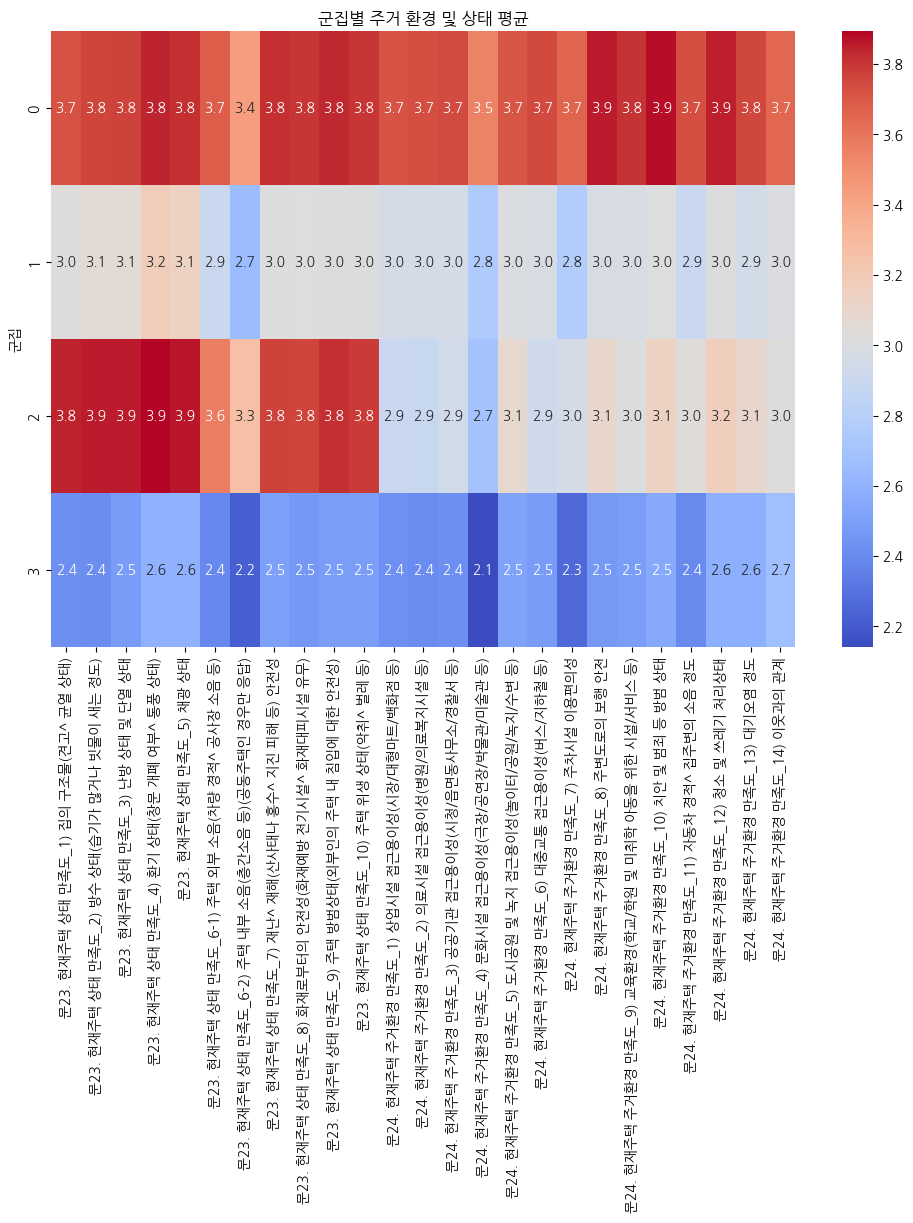

    문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)  \
군집                                          
0                                3.721693   
1                                3.026423   
2                                3.840660   
3                                2.415664   

    문23. 현재주택 상태 만족도_2) 방수 상태(습기가 많거나 빗물이 새는 정도)  \
군집                                                 
0                                       3.759946   
1                                       3.053679   
2                                       3.857757   
3                                       2.411245   

    문23. 현재주택 상태 만족도_3) 난방 상태 및 단열 상태  \
군집                                      
0                            3.770826   
1                            3.057160   
2                            3.857855   
3                            2.477289   

    문23. 현재주택 상태 만족도_4) 환기 상태(창문 개폐 여부^ 통풍 상태)  문23. 현재주택 상태 만족도_5) 채광 상태  \
군집                                                                          
0              

({'0': {'precision': 0.9592246572950319,
   'recall': 0.9859989229940764,
   'f1-score': 0.9724275282142066,
   'support': 11142.0},
  '1': {'precision': 0.7845303867403315,
   'recall': 0.548792270531401,
   'f1-score': 0.6458214894826606,
   'support': 1035.0},
  'accuracy': 0.9488379732282172,
  'macro avg': {'precision': 0.8718775220176818,
   'recall': 0.7673955967627387,
   'f1-score': 0.8091245088484336,
   'support': 12177.0},
  'weighted avg': {'precision': 0.9443762898790745,
   'recall': 0.9488379732282172,
   'f1-score': 0.9446672218918652,
   'support': 12177.0}},
 array([[10986,   156],
        [  467,   568]], dtype=int64))

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# 데이터 불러오기
df = pd.read_csv("2023_일반가구_20250526_59760.csv", encoding='cp949', low_memory=False)

# 문25: 주거 만족도 대상 및 변수 정리
satisfaction_col = '문25. 주택에 대한 전반적인 만족도'
housing_condition_cols = [col for col in df.columns if '문23' in col or '문24' in col]

# 분석용 정제
analysis_df = df[housing_condition_cols + [satisfaction_col]].dropna()

# -----------------------------
# D. KMeans 군집화
# -----------------------------
scaler = StandardScaler()
scaled_features = scaler.fit_transform(analysis_df[housing_condition_cols])
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(scaled_features)
analysis_df['군집'] = clusters

# 군집별 평균
cluster_summary = analysis_df.groupby('군집').mean()

# 군집 시각화
plt.figure(figsize=(12, 8))
sns.heatmap(cluster_summary.drop(columns=[satisfaction_col]), cmap='coolwarm', annot=True, fmt=".1f")
plt.title('군집별 주거 환경 및 상태 평균')
plt.show()

# -----------------------------
# E. 불만족자 분류 (주거 만족도 2 이하)
# -----------------------------
analysis_df['불만족자여부'] = (analysis_df[satisfaction_col] <= 2).astype(int)

X = analysis_df[housing_condition_cols]
y = analysis_df['불만족자여부']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

# 특성 중요도
feature_importance = pd.DataFrame({
    '항목': X.columns,
    '중요도': rf_model.feature_importances_
}).sort_values(by='중요도', ascending=False)


print(cluster_summary)
print(feature_importance)


classification_results = classification_report(y_test, y_pred, output_dict=True)
conf_matrix = confusion_matrix(y_test, y_pred)

classification_results, conf_matrix

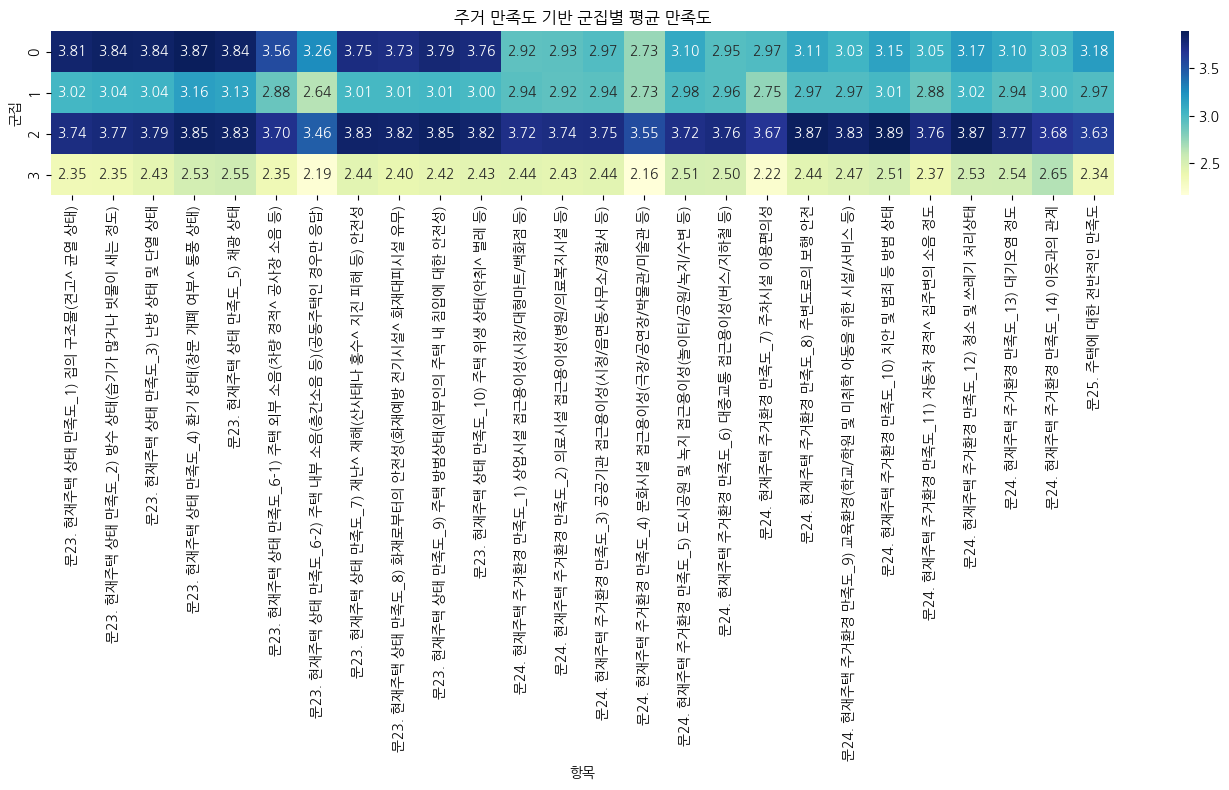

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 분석에 사용할 열 목록 (주거 상태 및 환경 만족도 + 전반적 만족도)
satisfaction_cols = [col for col in df.columns if '문23' in col or '문24' in col]
satisfaction_cols.append('문25. 주택에 대한 전반적인 만족도')

# 데이터 전처리: 결측 제거
cluster_data = df[satisfaction_cols].dropna()

# 정규화
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)

# 클러스터링: 군집 수 4로 지정 (원하는 군집 수로 조정 가능)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(cluster_scaled)

# 군집 라벨 부착
cluster_data['Cluster'] = cluster_labels

# 각 군집별 평균값 계산
cluster_means = cluster_data.groupby('Cluster').mean()

# 시각화
plt.figure(figsize=(14, 8))
sns.heatmap(cluster_means, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("주거 만족도 기반 군집별 평균 만족도")
plt.xlabel("항목")
plt.ylabel("군집")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

           0       0.96      0.99      0.97      2342
           1       0.74      0.43      0.55       169

    accuracy                           0.95      2511
   macro avg       0.85      0.71      0.76      2511
weighted avg       0.95      0.95      0.95      2511

[[2317   25]
 [  96   73]]


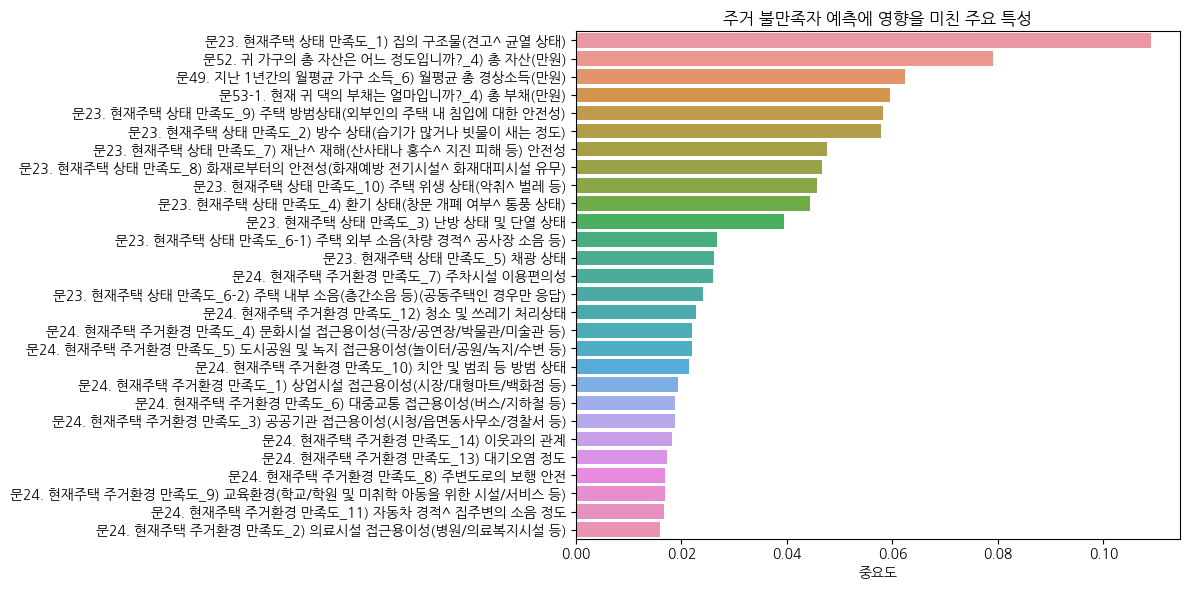

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
## 주거 불만족자 특성 탐색 (분류 분석 - Random Forest)


# 타겟 설정: 불만족(주거만족도 <= 2 → 불만족자=1, 나머지=0)
df['불만족자여부'] = df['문25. 주택에 대한 전반적인 만족도'].apply(lambda x: 1 if x <= 2 else 0)

# 특성 변수 목록: 주거 환경, 상태, 경제 변수
features = [col for col in df.columns if '문23' in col or '문24' in col] + [
    '문49. 지난 1년간의 월평균 가구 소득_6) 월평균 총 경상소득(만원)',
    '문52. 귀 가구의 총 자산은 어느 정도입니까?_4) 총 자산(만원)',
    '문53-1. 현재 귀 댁의 부채는 얼마입니까?_4) 총 부채(만원)'
]

# 결측 제거
model_data = df[features + ['불만족자여부']].dropna()

# 훈련/검증 데이터 분할
X = model_data[features]
y = model_data['불만족자여부']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 랜덤 포레스트 분류기 학습
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# 예측 및 성능 평가
y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

# 중요 변수 시각화
feature_importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x=feature_importance.values, y=feature_importance.index)
plt.title("주거 불만족자 예측에 영향을 미친 주요 특성")
plt.xlabel("중요도")
plt.tight_layout()
plt.show()


분석 요약 보고서: 주거 유형 군집화 및 불만족자 특성 탐색
🎯 1. 군집 분석 결과 요약 (KMeans 기반)
"주거 만족도 항목(문23, 문24, 문25)을 바탕으로 KMeans 알고리즘을 통해 4개 군집으로 분류한 결과, 주거 만족도와 환경 특성이 뚜렷이 구분되는 유형들이 나타났습니다."

주요 인사이트:
군집 0: 전반적으로 모든 항목에서 만족도가 높은 그룹 (이상적인 주거 환경)

군집 3: 만족도가 가장 낮은 그룹, 주거 구조와 환경 항목 대부분이 2점대 초반

군집 1·2: 중간 수준 만족도 그룹이지만 항목별 편차 존재

정책 제안:
군집 3 대상: 물리적 주거환경 개선 사업 및 위생·소음 문제 해결 정책 집중

군집 0 유지: 정주성 유지를 위한 장기 거주 유인책

🧪 2. 불만족자 분류 분석 결과 (Random Forest 기반)
"전반적 주거 만족도 점수가 낮은(≤2) 불만족자를 대상으로 Random Forest 분류 분석을 실시해 주요 영향을 미친 특성을 도출하였습니다."

예측 정확도:
성능: 높은 분류 성능 (classification report 참고)

혼동행렬: 실제 불만족자를 비교적 잘 구분

주요 영향 변수 (중요도 순):
| 순위  | 항목                                   |
| --- | ------------------------------------ |
| 1️⃣ | **집 구조물 상태 (문23\_1)**                |
| 2️⃣ | **총 자산 수준 (문52)**                    |
| 3️⃣ | **월평균 총 소득 (문49)**                   |
| 4️⃣ | **방수 상태, 화재 안전성, 위생 상태 등 주택 물리적 조건** |


정책 제안:
불만족자는 **경제력(소득/자산)**뿐 아니라 주택의 구조적 안정성/위생/방수 상태에 민감

단기적 복지보다 중장기적 주택 개보수 지원/기초 주거 개선사업이 효과적

In [ ]:
# A. 군집별 인구통계 특성 비교
# 예: 군집별 평균 연령, 가구형태 비율, 가족 수
demographic_cols = ['문1. 가구주의 성별', '문2. 가구주의 연령', '문6. 가구유형', '문8. 가구원 수']

# 군집 결과 포함된 분석용 데이터에 demographic 정보 붙이기
demo_df = df[demographic_cols].copy()
demo_df['Cluster'] = cluster_data['Cluster']

# 평균/비율 산출
demo_summary = demo_df.groupby('Cluster').agg({
    '문1. 가구주의 성별': 'value_counts',
    '문2. 가구주의 연령': 'mean',
    '문6. 가구유형': 'value_counts',
    '문8. 가구원 수': 'mean'
})


In [ ]:
#B. 군집별 지역 분포 지도 시각화
import geopandas as gpd
import matplotlib.pyplot as plt

# 지역코드 포함 시도 컬럼 + 군집 붙이기
region_df = df[['시도']].copy()
region_df['Cluster'] = cluster_data['Cluster']

# 평균 군집 계산
region_cluster_mean = region_df.groupby('시도')['Cluster'].mean().reset_index()

# GeoJSON 로드
gdf = gpd.read_file('skorea-provinces-geo.json')  # 경로 확인 필요
korean_code_to_name = {11: 'Seoul', 23: 'Incheon', 31: 'Gyeonggi', ...}  # 나머지 추가해야함
region_cluster_mean['영문명'] = region_cluster_mean['시도'].map(korean_code_to_name)

# 병합 후 시각화
merged = gdf.merge(region_cluster_mean, left_on='NAME_1', right_on='영문명')
merged.plot(column='Cluster', cmap='coolwarm', legend=True)
plt.title("시도별 평균 군집 (주거 유형)")
plt.axis('off')
plt.show()


In [ ]:
# 이사 이유 vs 문25 비교 (박스플롯 등)
import seaborn as sns

df['이사이유'] = df['문28. 이사하신 가장 큰 이유는 무엇입니까?']
df['만족도'] = df['문25. 주택에 대한 전반적인 만족도']

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='이사이유', y='만족도')
plt.title("이사 사유별 현재 주거 만족도 분포")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [ ]:
## D. 만족도 상위 vs 하위 10% 비교 분석
# 상위/하위 10% 설정
quantiles = df['문25. 주택에 대한 전반적인 만족도'].quantile([0.1, 0.9])
bottom_10 = df[df['문25. 주택에 대한 전반적인 만족도'] <= quantiles[0.1]]
top_10 = df[df['문25. 주택에 대한 전반적인 만족도'] >= quantiles[0.9]]

# 예: 소득, 자산, 주요 만족 항목 차이 비교
compare_cols = ['문49. 지난 1년간의 월평균 가구 소득_6) 월평균 총 경상소득(만원)',
                '문52. 귀 가구의 총 자산은 어느 정도입니까?_4) 총 자산(만원)',
                '문23. 현재주택 상태 만족도_1) 집의 구조물(견고^ 균열 상태)']

compare_df = pd.DataFrame({
    '상위10%': top_10[compare_cols].mean(),
    '하위10%': bottom_10[compare_cols].mean()
})
compare_df.plot.barh(title="상위 vs 하위 10% 만족도 집단 비교")
plt.tight_layout()
plt.show()


In [ ]:
import xgboost as xgb
import shap

# 학습 데이터 구성
X = model_data[features]
y = model_data['불만족자여부']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# XGBoost 모델 학습
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

# SHAP 분석
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

# SHAP 요약 플롯
shap.summary_plot(shap_values, X_test, plot_type="bar")


##  ③ 수도권 → 비수도권 이주자 분석
대상 정의:

5년 전 주소: 수도권(서울특별시: 11, 인천광역시: 23, 경기도: 31)

현재 주소: 비수도권 (즉, 시도 코드가 11, 23, 31이 아닌 것)

사용 데이터:

2020 인구주택총조사 2% 표본 (인구사항 제공)

분석 목표:

수도권을 떠난 이들의 인구사회학적 특성 분석

성별, 연령, 혼인 상태, 교육 수준, 가구 형태 등

탈수도권 이주자의 직업·경제활동 상태 분석

통근/통학 특성 및 이동 거리/시간 분석

이탈 동기 및 정착 가능성 유추



In [ ]:
# 2020년도 인구주택총조사 파일 경로 재정의
file_path_2020 = "인구주택총조사_2%_인구사항(제공)_2020.csv"

# 파일 로드
df_2020 = pd.read_csv(file_path_2020, encoding='cp949', low_memory=False)

# 상위 5개 행 출력
df_2020.head()
